# PCD_Assignment03
Farrel Fata Varian Nugraha
| 25/564457/PA/23770

## Setup


In [23]:
import re
import sys
import subprocess
from pathlib import Path
from urllib.parse import urlparse, parse_qs
from PIL import Image
import matplotlib.pyplot as plt

MAX_SIDE = 384


## Image Input


In [24]:
def load_image(url):
    address = urlparse(url)
    match = re.search(r"/file/d/([A-Za-z0-9_-]+)", address.path)
    file_id = match.group(1) if match else parse_qs(address.query).get("id", [""])[0]
    if address.hostname != "drive.google.com" or not re.fullmatch(r"[A-Za-z0-9_-]+", file_id):
        raise ValueError("Use a Google Drive file link.")
    try:
        import gdown
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown>=5.2,<7"])
        import gdown
    Path("images").mkdir(exist_ok=True)
    path = Path("images") / f"{file_id}.img"
    if not gdown.download(id=file_id, output=str(path), quiet=True):
        raise ValueError("Download failed. Check the file link and sharing permissions.")
    with Image.open(path) as source:
        rgba = source.convert("RGBA")
        width, height = rgba.size
        scale = min(1.0, MAX_SIDE / max(width, height))
        out_w, out_h = max(1, int(width*scale)), max(1, int(height*scale))
        pixels = rgba.load()
        image = []
        for y in range(out_h):
            row = []
            for x in range(out_w):
                red, green, blue, alpha = pixels[x*width//out_w, y*height//out_h]
                row.append(tuple((alpha*v + (255-alpha)*255 + 127)//255
                                 for v in (red, green, blue)))
            image.append(row)
    return image


## Grayscale Conversion


In [25]:
def grayscale(image):
    return [[(299*r + 587*g + 114*b + 500)//1000 for r, g, b in row]
            for row in image]


## Otsu Thresholding


In [26]:
def select_threshold(gray):
    histogram = [0]*256
    for row in gray:
        for value in row:
            histogram[value] += 1
    count = len(gray)*len(gray[0])
    total = sum(level*frequency for level, frequency in enumerate(histogram))
    lower_count = lower_sum = 0
    best_threshold = None
    best_numerator, best_denominator = -1, 1
    for threshold in range(255):
        lower_count += histogram[threshold]
        lower_sum += threshold*histogram[threshold]
        upper_count = count-lower_count
        if lower_count == 0 or upper_count == 0:
            continue
        numerator = (count*lower_sum - lower_count*total)**2
        denominator = lower_count*upper_count
        if numerator*best_denominator > best_numerator*denominator:
            best_threshold = threshold
            best_numerator, best_denominator = numerator, denominator
    if best_threshold is None:
        raise ValueError("Otsu requires at least two different intensity values.")
    return best_threshold


## Structuring Element


In [27]:
ELEMENT = [(dy, dx) for dy in (-1, 0, 1) for dx in (-1, 0, 1)]


## Erosion


In [28]:
def erode_points(points, element=ELEMENT):
    anchor_y, anchor_x = element[0]
    result = set()
    for y, x in points:
        center_y, center_x = y-anchor_y, x-anchor_x
        if all((center_y+dy, center_x+dx) in points for dy, dx in element):
            result.add((center_y, center_x))
    return result


## Dilation


In [29]:
def dilate_points(points, element=ELEMENT):
    return {(y+dy, x+dx) for y, x in points for dy, dx in element}


## Opening


In [30]:
def opening_points(points):
    return dilate_points(erode_points(points))


## Closing


In [31]:
def closing_points(points):
    return erode_points(dilate_points(points))


## Segmentation Comparison


In [32]:
def compare_results(image, name, foreground="bright"):
    if foreground not in ("bright", "dark"):
        raise ValueError("Foreground must be 'bright' or 'dark'.")
    gray = grayscale(image)
    threshold = select_threshold(gray)
    height, width = len(gray), len(gray[0])
    points = {(y, x) for y in range(height) for x in range(width)
              if (gray[y][x] > threshold) == (foreground == "bright")}
    regions = {
        "Otsu only": points,
        "Erosion": erode_points(points),
        "Dilation": dilate_points(points),
        "Opening": opening_points(points),
        "Closing": closing_points(points),
    }
    masks = {label: [[int((y, x) in region) for x in range(width)]
                     for y in range(height)] for label, region in regions.items()}
    panels = [("Original", image)] + list(masks.items())
    figure, axes = plt.subplots(2, 3, figsize=(12, 7), constrained_layout=True)
    for axis, (label, pixels) in zip(axes.flat, panels):
        if label == "Original":
            axis.imshow(pixels)
        else:
            axis.imshow(pixels, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axis.set_title(label)
        axis.axis("off")
    figure.suptitle(f"{name} | Threshold: {threshold} | Foreground: {foreground}")
    plt.show()
    plt.close(figure)
    return threshold, masks


## Run


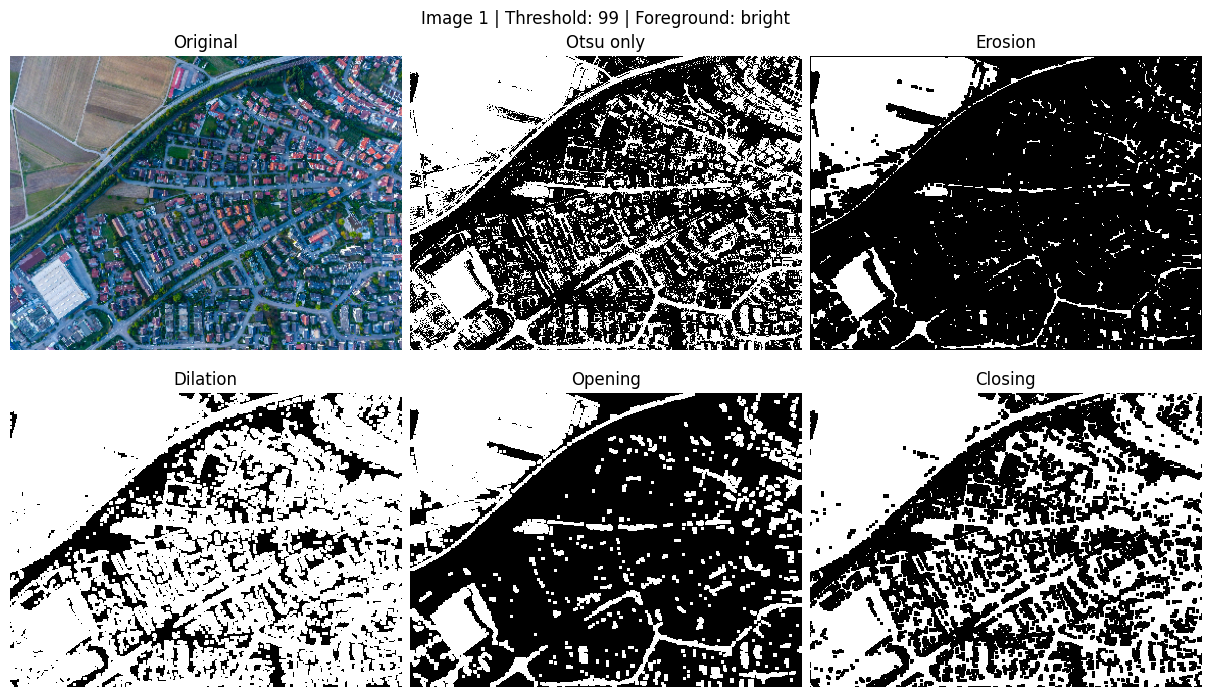

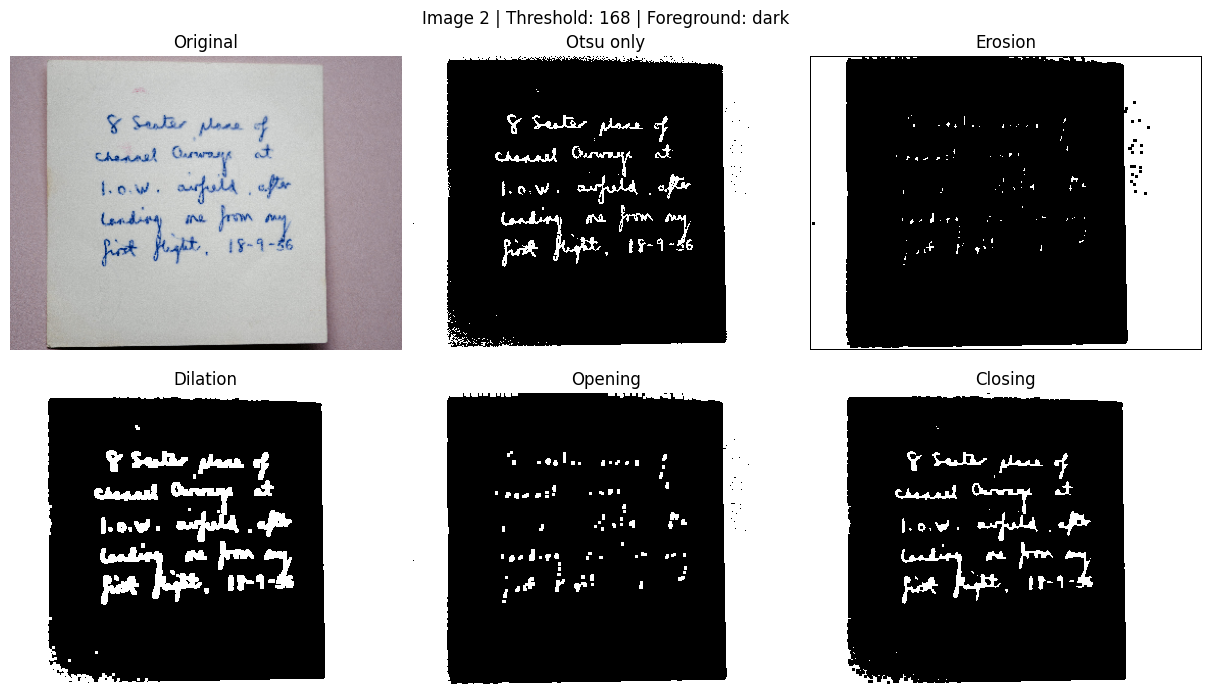

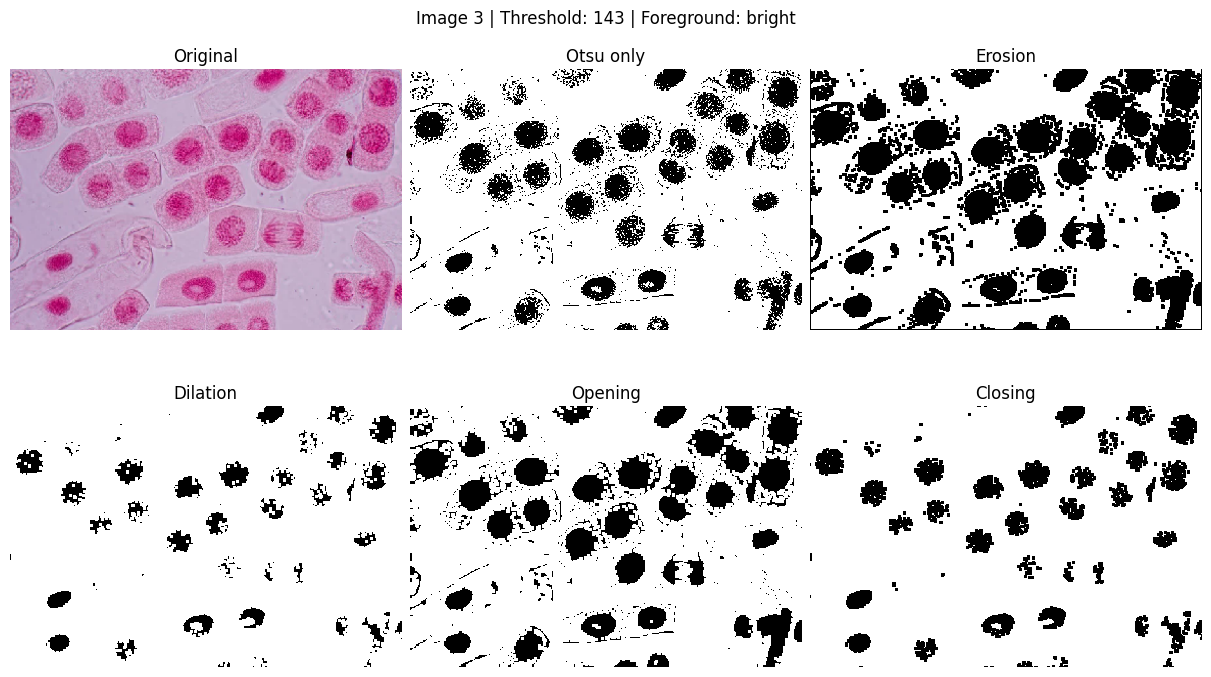

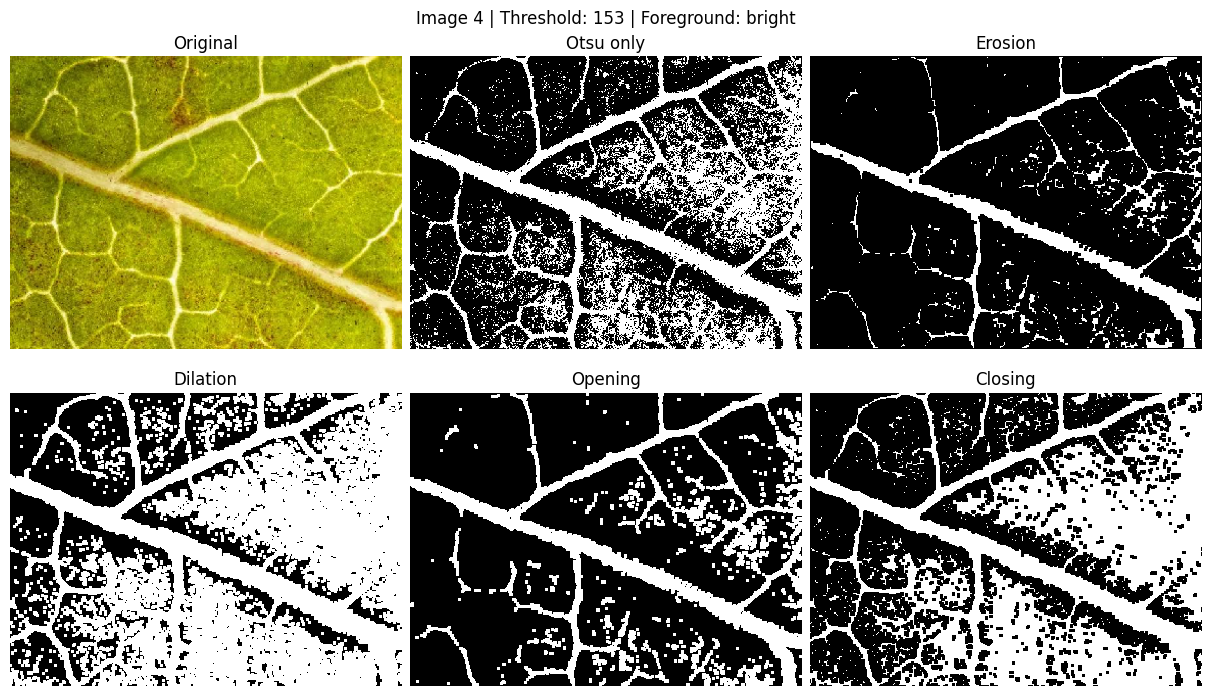

In [33]:
IMAGE_SOURCES = [
    ("Image 1", "https://drive.google.com/file/d/1h90cjnHreUUO-jvu2VCGnXvf7xYG6cgt/view?usp=drive_link"),
    ("Image 2", "https://drive.google.com/file/d/1ZdKKoTsiOh7TM8zCPivd16a3-38zo51c/view?usp=drive_link"),
    ("Image 3", "https://drive.google.com/file/d/1WzuVvHeGbp7fgQtcx70tB_6W2QzaDd21/view?usp=drive_link"),
    ("Image 4", "https://drive.google.com/file/d/1ZZduH8KpZGvD2Pu7KlAlhbTfrdH3R4v2/view?usp=drive_link"),
]

for name, url in IMAGE_SOURCES:
    try:
        compare_results(load_image(url), name, FOREGROUND.get(name, "bright"))
    except Exception as error:
        print(f"{name}: {error}")